# TRENIRANJE LONG SHORT-TERM MEMORY MODELA

### Priprema modela

In [29]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from datetime import datetime
import matplotlib.pyplot as plt

# Učitaj podatke
df = pd.read_csv("output/spojeni_podaci.csv")
df = df.dropna(subset=["PV Yield (kWh)"])

# Pretvori datum
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df = df.dropna(subset=["Date"])
df = df.sort_values("Date").reset_index(drop=True)


# Izvuci vremenske značajke
df["dan_u_tjednu"] = df["Date"].dt.dayofweek
df["mjesec"] = df["Date"].dt.month
df["dan_u_godini"] = df["Date"].dt.dayofyear

# Inženjering značajki (omjer temperature i naoblake — gdje ima smisla)
df["temp_naoblaka_ratio"] = df["temperatura"] / (df["naoblaka"] + 1e-5)

# Značajke  
features = [
    "insolacija", "temperatura", "Peak Power (kW)",
    "Specific Energy (kWh/kWp)",
    "dan_u_tjednu", "mjesec", "dan_u_godini", "temp_naoblaka_ratio"
]
target = "PV Yield (kWh)"

df = df[features + [target]].dropna()

# Skaliranje
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_scaled = scaler_X.fit_transform(df[features])
y_scaled = scaler_y.fit_transform(df[[target]]).flatten()

# LSTM zahtijeva sekvencijalne ulaze
def create_sequences(X, y, seq_length=20):
    X_seq, y_seq = [], []
    for i in range(len(X) - seq_length):
        X_seq.append(X[i:i+seq_length])
        y_seq.append(y[i+seq_length])
    return np.array(X_seq), np.array(y_seq)

X_seq, y_seq = create_sequences(X_scaled, y_scaled)

### Podjela setova

In [30]:
# Train/test split
split_idx = int(0.8 * len(X_seq))
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# Tensor konverzija
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

# Dataset i DataLoader
train_ds = TensorDataset(X_train_tensor, y_train_tensor)
train_dl = DataLoader(train_ds, batch_size=16, shuffle=True)

### Inicijalizacija modela 

In [31]:

# LSTM Model
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size=128, num_layers=1, dropout=0.0):
        super(LSTMModel, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers,
                            batch_first=True, dropout=0.0)
        self.fc = nn.Sequential(
            nn.BatchNorm1d(hidden_size),
            nn.Linear(hidden_size, 1)
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]
        out = self.fc(out)
        return out

 # Inicijalizacija
model = LSTMModel(input_size=X_train.shape[2])
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)

### Treniranje

In [32]:
# Treniranje
n_epochs = 100
for epoch in range(n_epochs):
    model.train()
    for X_batch, y_batch in train_dl:
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = loss_fn(y_pred, y_batch)
        loss.backward()
        optimizer.step()
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}/{n_epochs}, Loss: {loss.item():.4f}")



Epoch 10/100, Loss: 0.0172
Epoch 20/100, Loss: 0.0897
Epoch 30/100, Loss: 0.0732
Epoch 40/100, Loss: 0.0906
Epoch 50/100, Loss: 0.0495
Epoch 60/100, Loss: 0.0222
Epoch 70/100, Loss: 0.0133
Epoch 80/100, Loss: 0.0452
Epoch 90/100, Loss: 0.0359
Epoch 100/100, Loss: 0.0353


### Evaluacija modela

In [ ]:
# === Evaluacija ===
model.eval()
with torch.no_grad():
    y_pred_scaled = model(X_test_tensor).numpy()
    y_true_scaled = y_test_tensor.numpy()

# Inverzna transformacija predikcija i stvarnih vrijednosti
y_pred_inv = scaler_y.inverse_transform(y_pred_scaled)
y_true_inv = scaler_y.inverse_transform(y_true_scaled)

# === Korelacija ===
from scipy.stats import pearsonr

corr, _ = pearsonr(y_true_inv.flatten(), y_pred_inv.flatten())
print(f"\nPearsonova korelacija između predikcija i stvarnih vrijednosti: {corr:.4f}")

# === Metrike ===
mae = mean_absolute_error(y_true_inv, y_pred_inv)
mse = mean_squared_error(y_true_inv, y_pred_inv)
r2 = r2_score(y_true_inv, y_pred_inv)

print("\nEvaluacija LSTM modela:")
print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"R²: {r2:.2f}")


📈 Pearsonova korelacija između predikcija i stvarnih vrijednosti: 0.7350

📊 Evaluacija LSTM modela:
MAE: 4.52
MSE: 32.73
R²: 0.48


### Vizualizacija

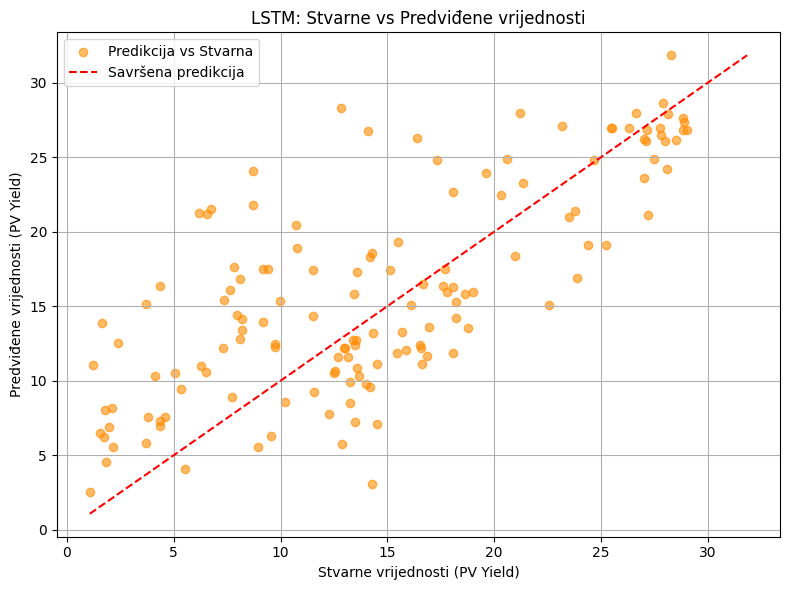

In [34]:
# === Scatter graf ===
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_true_inv, y_pred_inv, alpha=0.6, color="darkorange", label="Predikcija vs Stvarna")
lims = [min(y_true_inv.min(), y_pred_inv.min()), max(y_true_inv.max(), y_pred_inv.max())]
plt.plot(lims, lims, 'r--', label='Savršena predikcija')
plt.xlabel("Stvarne vrijednosti (PV Yield)")
plt.ylabel("Predviđene vrijednosti (PV Yield)")
plt.title("LSTM: Stvarne vs Predviđene vrijednosti")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("grafovi/LSTM.png")
plt.show()

## FINE-TUNIN LSTM MODELA

### Trazenje najboljih parametara

In [35]:
from itertools import product

hidden_sizes = [64, 128]
num_layers_list = [1, 2]
learning_rates = [0.001, 0.005]
batch_sizes = [16, 32]

best_score = -np.inf
best_params = {}

for hidden_size, num_layers, lr, batch_size in product(hidden_sizes, num_layers_list, learning_rates, batch_sizes):
    dropout_rate = 0.3 if num_layers > 1 else 0.0
    model = LSTMModel(input_size=X_train.shape[2], hidden_size=hidden_size, num_layers=num_layers)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    train_ds = TensorDataset(X_train_tensor, y_train_tensor)
    train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True)

    # Trening (manje epoha za brzo ispitivanje)
    for epoch in range(30):
        model.train()
        for X_batch, y_batch in train_dl:
            optimizer.zero_grad()
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        y_pred = model(X_test_tensor).numpy()
        y_pred_inv = scaler_y.inverse_transform(y_pred)
        y_true_inv = scaler_y.inverse_transform(y_test_tensor.numpy())
        r2 = r2_score(y_true_inv, y_pred_inv)

        if r2 > best_score:
            best_score = r2
            best_params = {
                "hidden_size": hidden_size,
                "num_layers": num_layers,
                "lr": lr,
                "batch_size": batch_size
            }

print("Najbolji rezultat:", best_score)
print("Najbolji hiperparametri:", best_params)

Najbolji rezultat: 0.5622005462646484
Najbolji hiperparametri: {'hidden_size': 64, 'num_layers': 1, 'lr': 0.005, 'batch_size': 16}
